In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dados-brutos-estruturados.xlsx to dados-brutos-estruturados.xlsx


In [ ]:
file_name = next(iter(uploaded))

raw = pd.read_excel(file_name, header=None)

print("Raw Dataset:")
display(raw.head(10))

print("Shape:", raw.shape)

Raw Dataset:


,0
0,"Datas,dia_semana,Demandas,Classe"
1,"01/01/2013,ter,25125,ferias"
2,"02/01/2013,qua,105630,ferias"
3,"03/01/2013,qui,110150,ferias"
4,"04/01/2013,sex,110242,ferias"
5,"05/01/2013,sab,71226,ferias"
6,"06/01/2013,dom,35261,ferias"
7,"07/01/2013,seg,128871,ferias"
8,"08/01/2013,ter,128574,ferias"
9,"09/01/2013,qua,122306,ferias"


Shape: (1462, 1)


In [ ]:
df = raw[0].str.split(',', expand=True)

df.columns = df.iloc[0].str.strip()

df = df.iloc[1:].reset_index(drop=True)

display(df.head())

,Datas,dia_semana,Demandas,Classe
0,01/01/2013,ter,25125,ferias
1,02/01/2013,qua,105630,ferias
2,03/01/2013,qui,110150,ferias
3,04/01/2013,sex,110242,ferias
4,05/01/2013,sab,71226,ferias


In [ ]:
df.columns = df.columns.str.strip()

df['Datas'] = pd.to_datetime(
    df['Datas'], dayfirst=True
)

df['Demandas'] = pd.to_numeric(df['Demandas'])

df['dia_semana'] = df['dia_semana'].str.strip()
df['Classe'] = df['Classe'].str.strip()

print(df.dtypes)
display(df.head())

0
Datas         datetime64[ns]
dia_semana            object
Demandas               int64
Classe                object
dtype: object


,Datas,dia_semana,Demandas,Classe
0,2013-01-01,ter,25125,ferias
1,2013-01-02,qua,105630,ferias
2,2013-01-03,qui,110150,ferias
3,2013-01-04,sex,110242,ferias
4,2013-01-05,sab,71226,ferias


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape: (1461, 4)

Column Names:
['Datas', 'dia_semana', 'Demandas', 'Classe']

Data Types:
0
Datas         datetime64[ns]
dia_semana            object
Demandas               int64
Classe                object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Datas       1461 non-null   datetime64[ns]
 1   dia_semana  1461 non-null   object        
 2   Demandas    1461 non-null   int64         
 3   Classe      1461 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 45.8+ KB


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDuplicate Dates:")
print(df['Datas'].duplicated().sum())

Missing Values:
0
Datas         0
dia_semana    0
Demandas      0
Classe        0
dtype: int64

Duplicate Rows:
0

Duplicate Dates:
0


In [ ]:
print("Statistical Summary:")
display(df.describe())

print("\nDay-wise Passenger Records:")
print(df['dia_semana'].value_counts())

print("\nClass-wise Records:")
print(df['Classe'].value_counts())

Statistical Summary:


,Datas,Demandas
count,1461,1461.000000
mean,2015-01-01 00:00:00,99927.079398
min,2013-01-01 00:00:00,0.000000
25%,2014-01-01 00:00:00,71386.000000
50%,2015-01-01 00:00:00,112591.000000
75%,2016-01-01 00:00:00,131729.000000
max,2016-12-31 00:00:00,154774.000000
std,NaN,38165.972929



Day-wise Passenger Records:
dia_semana
ter    209
qua    209
qui    209
sex    209
sab    209
dom    208
seg    208
Name: count, dtype: int64

Class-wise Records:
Classe
dia letivo    1199
ferias         262
Name: count, dtype: int64


In [ ]:

# Rename columns into English
df = df.rename(columns={
    'Datas': 'Date',
    'dia_semana': 'Day_of_Week',
    'Demandas': 'Passenger_Count',
    'Classe': 'Day_Type'
})

# Translate weekdays
day_mapping = {
    'seg': 'Monday',
    'ter': 'Tuesday',
    'qua': 'Wednesday',
    'qui': 'Thursday',
    'sex': 'Friday',
    'sab': 'Saturday',
    'dom': 'Sunday'
}

df['Day_of_Week'] = df['Day_of_Week'].map(day_mapping)

# Translate day classifications
class_mapping = {
    'dia letivo': 'Working Day',
    'ferias': 'Vacation'
}

df['Day_Type'] = df['Day_Type'].map(class_mapping)

# Display updated dataset
display(df.head(10))

print(df.columns.tolist())


,Date,Day_of_Week,Passenger_Count,Day_Type
0,2013-01-01,Tuesday,25125,Vacation
1,2013-01-02,Wednesday,105630,Vacation
2,2013-01-03,Thursday,110150,Vacation
3,2013-01-04,Friday,110242,Vacation
4,2013-01-05,Saturday,71226,Vacation
5,2013-01-06,Sunday,35261,Vacation
6,2013-01-07,Monday,128871,Vacation
7,2013-01-08,Tuesday,128574,Vacation
8,2013-01-09,Wednesday,122306,Vacation
9,2013-01-10,Thursday,122593,Vacation


['Date', 'Day_of_Week', 'Passenger_Count', 'Day_Type']


In [ ]:
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

print("\nDate Range:")
print(df['Date'].min(), "to", df['Date'].max())

print("\nAverage Passengers:", df['Passenger_Count'].mean())
print("Minimum Passengers:", df['Passenger_Count'].min())
print("Maximum Passengers:", df['Passenger_Count'].max())

print("\nDay-wise Average Passenger Count:")
display(
    df.groupby('Day_of_Week')['Passenger_Count']
    .mean()
    .reindex([
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ])
)

Total Records: 1461
Total Columns: 4

Date Range:
2013-01-01 00:00:00 to 2016-12-31 00:00:00

Average Passengers: 99927.07939767283
Minimum Passengers: 0
Maximum Passengers: 154774

Day-wise Average Passenger Count:


,Passenger_Count
Day_of_Week,
Monday,122109.399038
Tuesday,122352.789474
Wednesday,119753.837321
Thursday,116247.086124
Friday,115162.976077
Saturday,69829.698565
Sunday,33823.620192


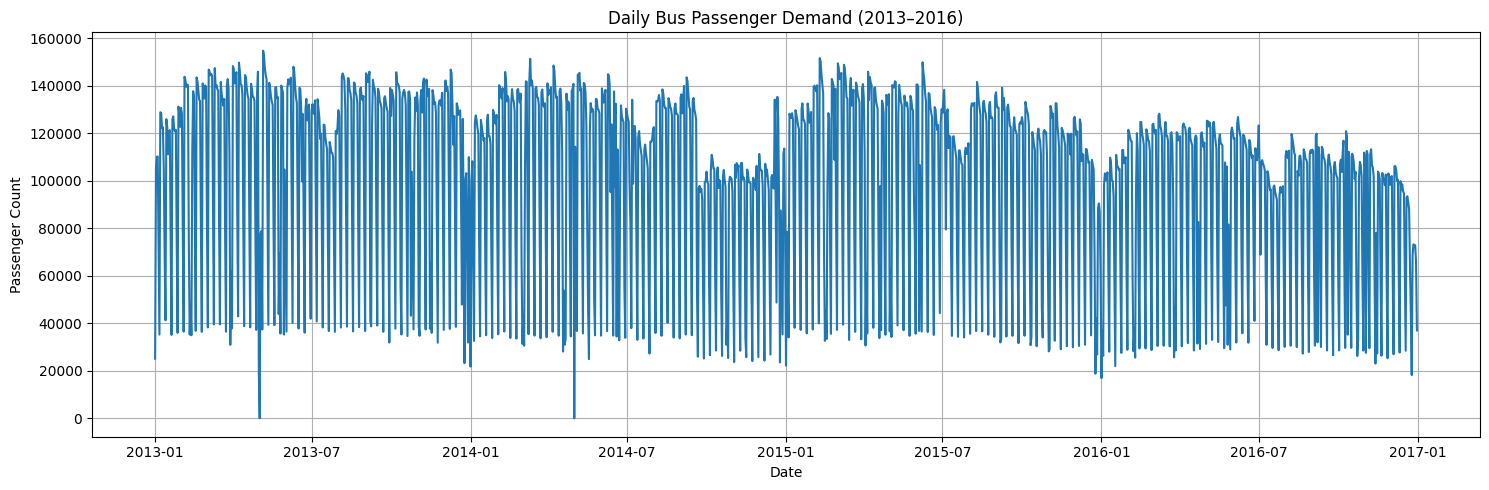

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    df['Date'],
    df['Passenger_Count']
)

plt.title('Daily Bus Passenger Demand (2013–2016)')
plt.xlabel('Date')
plt.ylabel('Passenger Count')

plt.grid(True)
plt.tight_layout()
plt.show()

Average Passenger Demand by Day:


,Passenger_Count
Day_of_Week,
Monday,122109.399038
Tuesday,122352.789474
Wednesday,119753.837321
Thursday,116247.086124
Friday,115162.976077
Saturday,69829.698565
Sunday,33823.620192


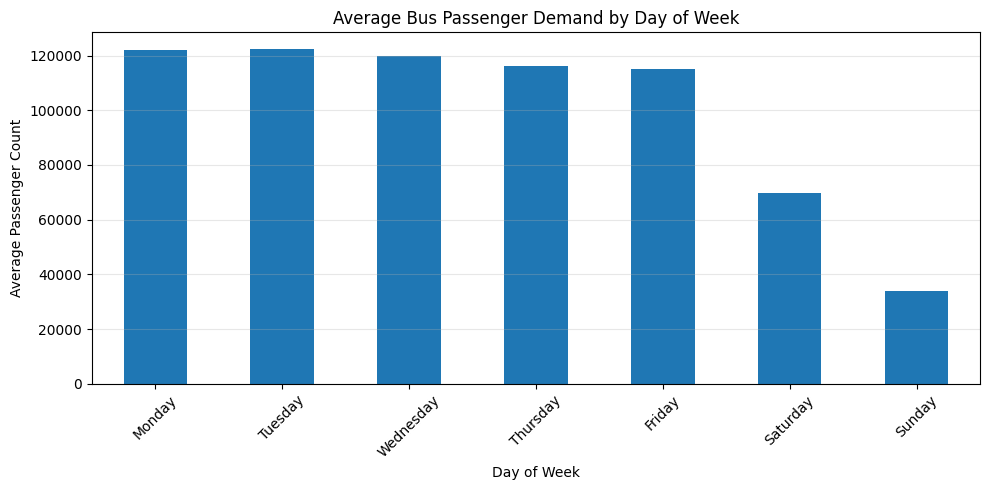

In [ ]:

# Define weekday order
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

# Calculate average passenger demand
daily_avg = (
    df.groupby('Day_of_Week')['Passenger_Count']
    .mean()
    .reindex(weekday_order)
)

print("Average Passenger Demand by Day:")
display(daily_avg)

# Create bar chart
plt.figure(figsize=(10, 5))

daily_avg.plot(kind='bar')

plt.title('Average Bus Passenger Demand by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Passenger Count')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


Average Passenger Demand by Day Type:


,Passenger_Count
Day_Type,
Vacation,91678.374046
Working Day,101729.548791


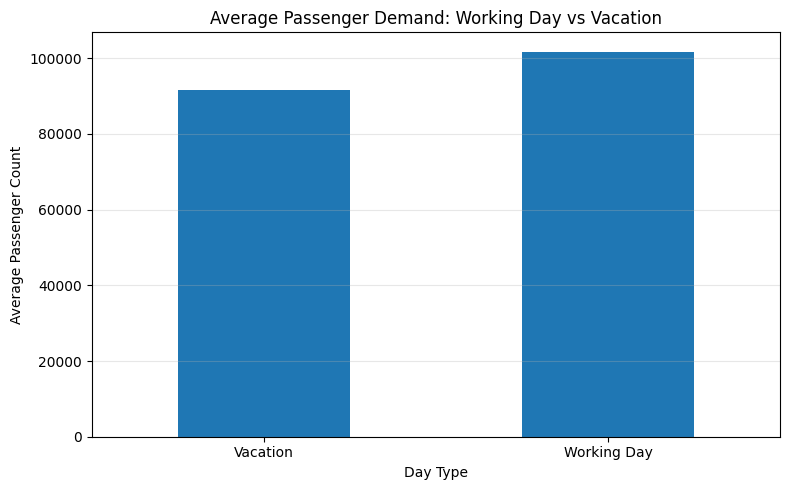

In [ ]:

class_avg = df.groupby('Day_Type')['Passenger_Count'].mean()

print("Average Passenger Demand by Day Type:")
display(class_avg)

plt.figure(figsize=(8, 5))

class_avg.plot(kind='bar')

plt.title('Average Passenger Demand: Working Day vs Vacation')
plt.xlabel('Day Type')
plt.ylabel('Average Passenger Count')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


<Figure size 900x500 with 0 Axes>

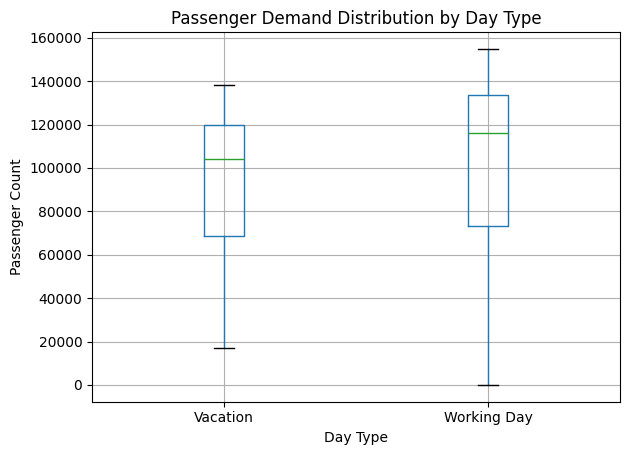

In [ ]:

plt.figure(figsize=(9, 5))

df.boxplot(
    column='Passenger_Count',
    by='Day_Type'
)

plt.title('Passenger Demand Distribution by Day Type')
plt.suptitle('')
plt.xlabel('Day Type')
plt.ylabel('Passenger Count')

plt.tight_layout()
plt.show()


Average Passenger Demand by Month:


,Passenger_Count
January,96037.846774
February,104559.690265
March,106656.104839
April,106574.033333
May,100331.798387
June,104831.450000
July,98410.887097
August,105914.120968
September,101914.466667
October,93856.266129


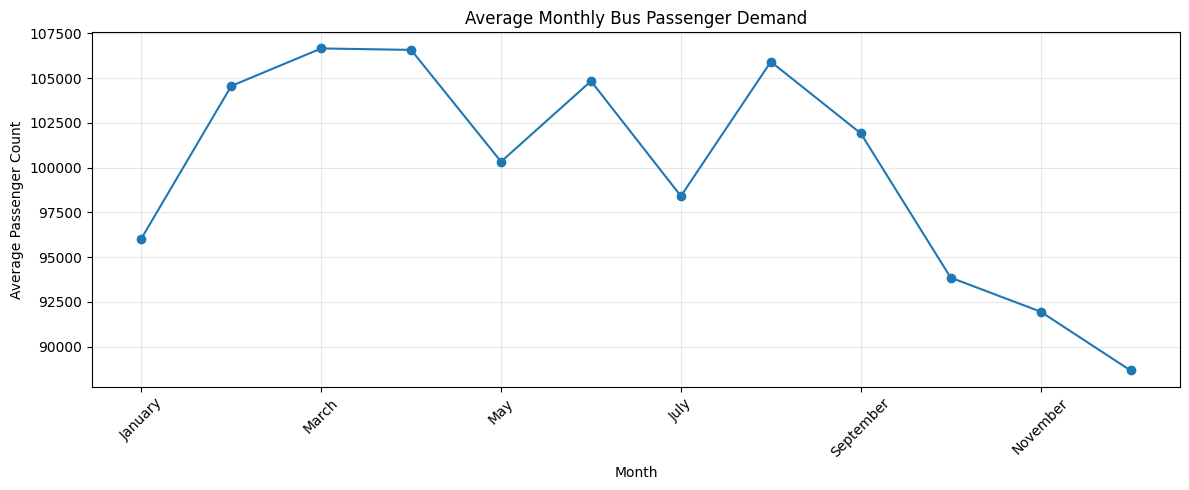

In [ ]:

df['Month'] = df['Date'].dt.month

monthly_avg = df.groupby('Month')['Passenger_Count'].mean()

month_names = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_avg.index = month_names

print("Average Passenger Demand by Month:")
display(monthly_avg)

plt.figure(figsize=(12, 5))

monthly_avg.plot(kind='line', marker='o')

plt.title('Average Monthly Bus Passenger Demand')
plt.xlabel('Month')
plt.ylabel('Average Passenger Count')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


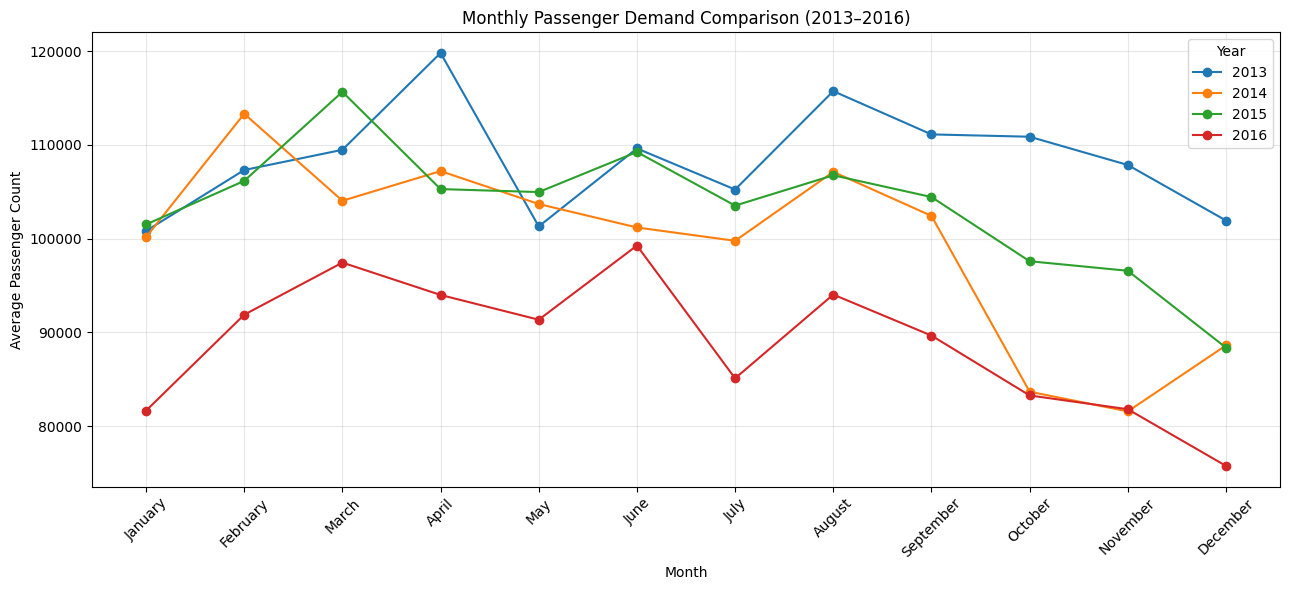

In [ ]:

df['Year'] = df['Date'].dt.year

year_month_avg = df.pivot_table(
    index='Month',
    columns='Year',
    values='Passenger_Count',
    aggfunc='mean'
)

plt.figure(figsize=(13, 6))

for year in year_month_avg.columns:
    plt.plot(
        month_names,
        year_month_avg[year],
        marker='o',
        label=str(year)
    )

plt.title('Monthly Passenger Demand Comparison (2013–2016)')
plt.xlabel('Month')
plt.ylabel('Average Passenger Count')
plt.xticks(rotation=45)
plt.legend(title='Year')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


,Total_Passengers,Average_Passengers,Minimum_Passengers,Maximum_Passengers
Year,,,,
2013,39564176,108395.002740,0,154774
2014,36244960,99301.260274,0,151349
2015,37709416,103313.468493,18792,151650
2016,32474911,88729.265027,16931,128251


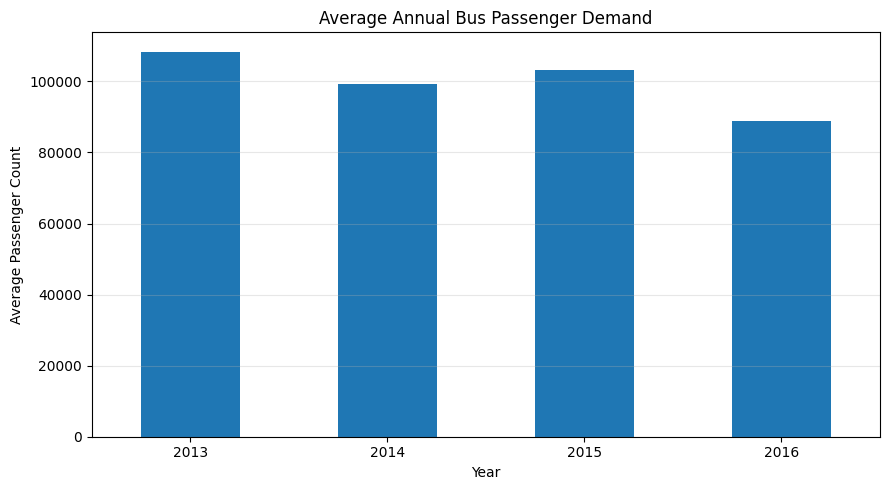

In [ ]:

yearly_summary = df.groupby('Year')['Passenger_Count'].agg(
    Total_Passengers='sum',
    Average_Passengers='mean',
    Minimum_Passengers='min',
    Maximum_Passengers='max'
)

display(yearly_summary)

# Yearly average passenger demand
plt.figure(figsize=(9, 5))

yearly_summary['Average_Passengers'].plot(
    kind='bar',
    rot=0
)

plt.title('Average Annual Bus Passenger Demand')
plt.xlabel('Year')
plt.ylabel('Average Passenger Count')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


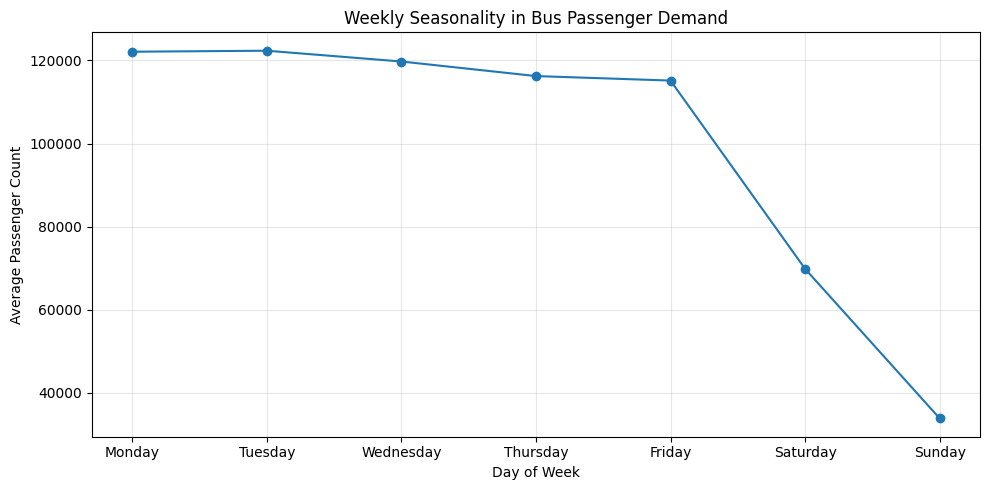

In [ ]:

df['Day_Number'] = df['Date'].dt.dayofweek

weekly_avg = df.groupby('Day_Number')['Passenger_Count'].mean()

weekly_avg.index = weekday_order

plt.figure(figsize=(10, 5))

plt.plot(
    weekly_avg.index,
    weekly_avg.values,
    marker='o'
)

plt.title('Weekly Seasonality in Bus Passenger Demand')
plt.xlabel('Day of Week')
plt.ylabel('Average Passenger Count')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# Sort data by date
df = df.sort_values('Date')

# Set Date as index
ts = df.set_index('Date')['Passenger_Count']

# Ensure daily frequency
ts = ts.asfreq('D')

print(ts.head())
print("\nFrequency:", ts.index.freq)
print("Missing values:", ts.isnull().sum())

Date
2013-01-01     25125
2013-01-02    105630
2013-01-03    110150
2013-01-04    110242
2013-01-05     71226
Freq: D, Name: Passenger_Count, dtype: int64

Frequency: <Day>
Missing values: 0


In [ ]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(ts.dropna())

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(key, ":", value)

if adf_result[1] <= 0.05:
    print("\nThe time series is stationary.")
else:
    print("\nThe time series is non-stationary.")

ADF Statistic: -3.8758070249002934
P-value: 0.002220287053823569
Critical Values:
1% : -3.4349024693573584
5% : -2.8635506057382325
10% : -2.5678404322793846

The time series is stationary.


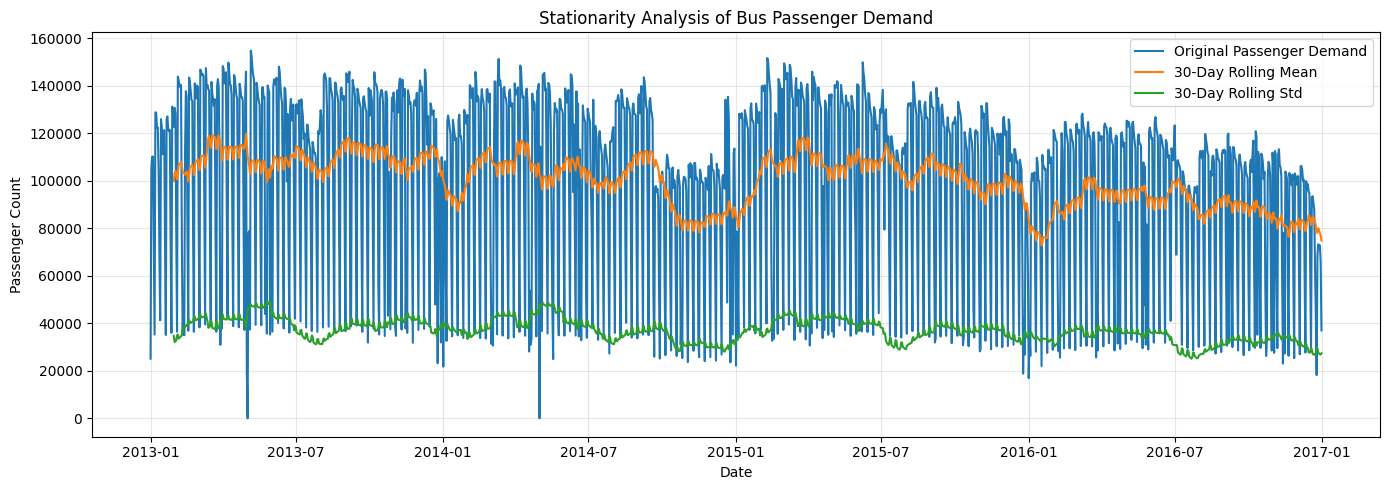

In [ ]:
rolling_mean = ts.rolling(window=30).mean()
rolling_std = ts.rolling(window=30).std()

plt.figure(figsize=(14, 5))

plt.plot(ts, label='Original Passenger Demand')
plt.plot(rolling_mean, label='30-Day Rolling Mean')
plt.plot(rolling_std, label='30-Day Rolling Std')

plt.title('Stationarity Analysis of Bus Passenger Demand')
plt.xlabel('Date')
plt.ylabel('Passenger Count')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

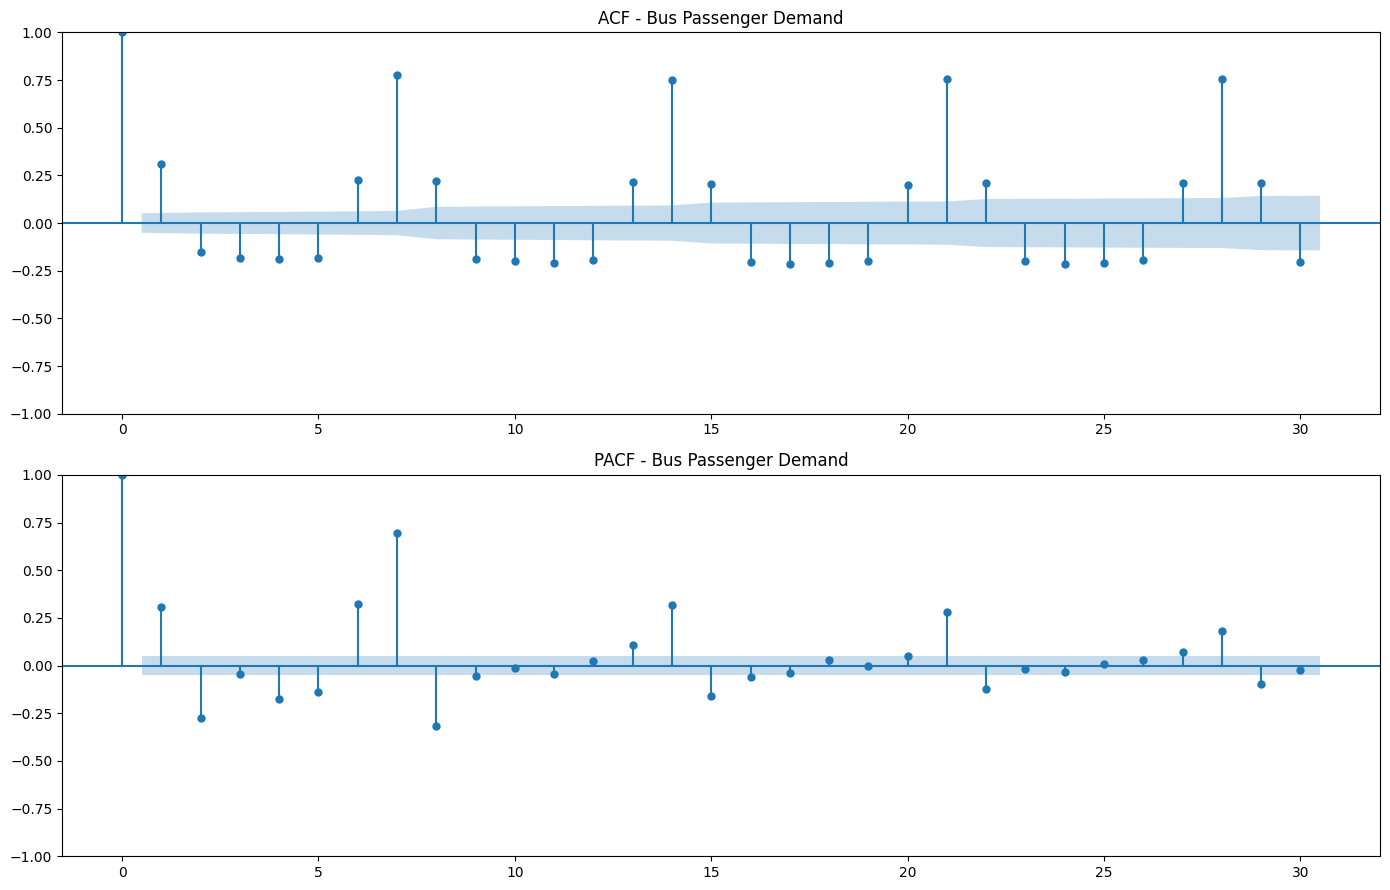

In [ ]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(ts.dropna(), lags=30, ax=axes[0])
axes[0].set_title('ACF - Bus Passenger Demand')

plot_pacf(ts.dropna(), lags=30, ax=axes[1], method='ywm')
axes[1].set_title('PACF - Bus Passenger Demand')

plt.tight_layout()
plt.show()


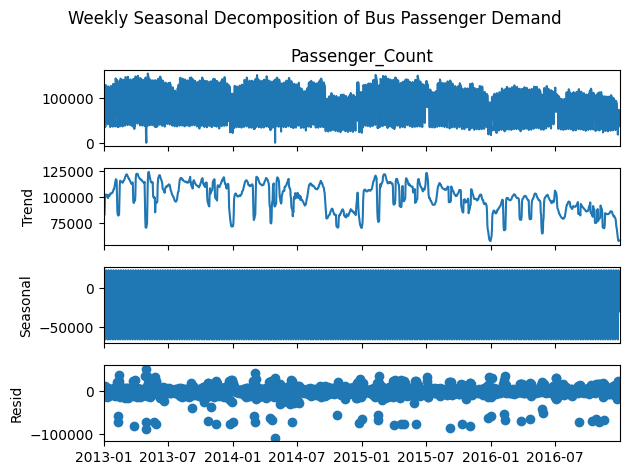

In [ ]:

from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    ts.dropna(),
    model='additive',
    period=7
)

decomposition.plot()
plt.suptitle('Weekly Seasonal Decomposition of Bus Passenger Demand')
plt.tight_layout()
plt.show()


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [4]:
from google.colab import files

uploaded = files.upload()

raw = pd.read_excel(next(iter(uploaded)), header=None)

print(raw.head())

Saving dados-brutos-estruturados.xlsx to dados-brutos-estruturados.xlsx
                                  0
0  Datas,dia_semana,Demandas,Classe
1       01/01/2013,ter,25125,ferias
2      02/01/2013,qua,105630,ferias
3      03/01/2013,qui,110150,ferias
4      04/01/2013,sex,110242,ferias


In [5]:
df = raw[0].str.split(',', expand=True)

df.columns = df.iloc[0].str.strip()
df = df.iloc[1:].reset_index(drop=True)

df.columns = df.columns.str.strip()

print(df.head())
print(df.shape)

0       Datas dia_semana Demandas  Classe
0  01/01/2013        ter    25125  ferias
1  02/01/2013        qua   105630  ferias
2  03/01/2013        qui   110150  ferias
3  04/01/2013        sex   110242  ferias
4  05/01/2013        sab    71226  ferias
(1461, 4)


In [6]:
df['Datas'] = pd.to_datetime(df['Datas'], dayfirst=True)
df['Demandas'] = pd.to_numeric(df['Demandas'])

df = df.rename(columns={
    'Datas': 'Date',
    'dia_semana': 'Day_of_Week',
    'Demandas': 'Passenger_Count',
    'Classe': 'Day_Type'
})

day_mapping = {
    'seg': 'Monday',
    'ter': 'Tuesday',
    'qua': 'Wednesday',
    'qui': 'Thursday',
    'sex': 'Friday',
    'sab': 'Saturday',
    'dom': 'Sunday'
}

class_mapping = {
    'dia letivo': 'Working Day',
    'ferias': 'Vacation'
}

df['Day_of_Week'] = df['Day_of_Week'].str.strip().map(day_mapping)
df['Day_Type'] = df['Day_Type'].str.strip().map(class_mapping)

df = df.sort_values('Date').reset_index(drop=True)

print(df.head())
print(df.shape)

0       Date Day_of_Week  Passenger_Count  Day_Type
0 2013-01-01     Tuesday            25125  Vacation
1 2013-01-02   Wednesday           105630  Vacation
2 2013-01-03    Thursday           110150  Vacation
3 2013-01-04      Friday           110242  Vacation
4 2013-01-05    Saturday            71226  Vacation
(1461, 4)


In [7]:
df = df.sort_values('Date')

ts = df.set_index('Date')['Passenger_Count'].asfreq('D')

print(ts.head())
print("Missing values:", ts.isnull().sum())
print("Total days:", len(ts))

Date
2013-01-01     25125
2013-01-02    105630
2013-01-03    110150
2013-01-04    110242
2013-01-05     71226
Freq: D, Name: Passenger_Count, dtype: int64
Missing values: 0
Total days: 1461


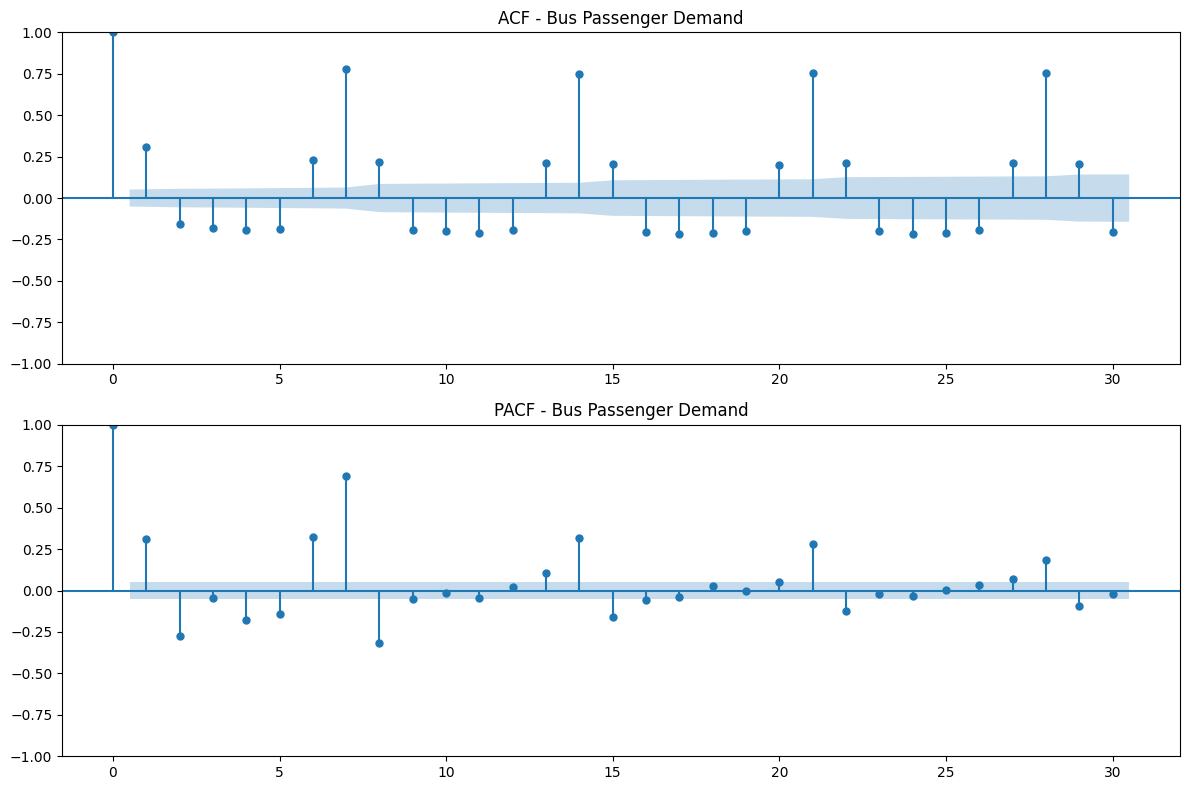

In [8]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(ts, lags=30, ax=axes[0])
axes[0].set_title("ACF - Bus Passenger Demand")

plot_pacf(ts, lags=30, method='ywm', ax=axes[1])
axes[1].set_title("PACF - Bus Passenger Demand")

plt.tight_layout()
plt.show()

In [9]:
train = ts[:'2016-05-31']
test = ts['2016-06-01':'2016-06-30']

print("Training records:", len(train))
print("Testing records:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training records: 1247
Testing records: 30
Training period: 2013-01-01 00:00:00 to 2016-05-31 00:00:00
Testing period: 2016-06-01 00:00:00 to 2016-06-30 00:00:00


In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = model.fit(disp=False)

print(sarima_result.summary())

                                     SARIMAX Results                                     
Dep. Variable:                   Passenger_Count   No. Observations:                 1247
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood              -14491.864
Date:                           Fri, 20 Nov 2026   AIC                          28993.728
Time:                                   03:23:28   BIC                          29019.335
Sample:                               01-01-2013   HQIC                         29003.359
                                    - 05-31-2016                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6836      0.172      3.977      0.000       0.347       1.021
ma.L1         -0.2290      0.198     -1.158

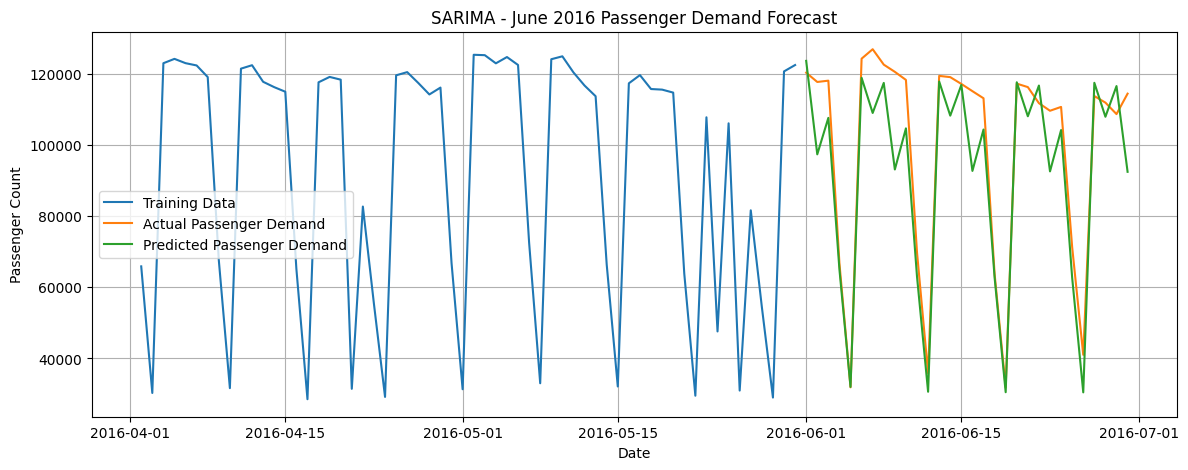

In [11]:
forecast_result = sarima_result.get_forecast(steps=len(test))

forecast = forecast_result.predicted_mean
forecast.index = test.index

plt.figure(figsize=(14, 5))
plt.plot(train[-60:], label='Training Data')
plt.plot(test, label='Actual Passenger Demand')
plt.plot(forecast, label='Predicted Passenger Demand')

plt.title('SARIMA - June 2016 Passenger Demand Forecast')
plt.xlabel('Date')
plt.ylabel('Passenger Count')
plt.legend()
plt.grid()
plt.show()

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("SARIMA Model Evaluation")
print("-----------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

SARIMA Model Evaluation
-----------------------
MAE: 8574.28
RMSE: 11262.1


In [13]:
results = pd.DataFrame({
    'Date': test.index,
    'Actual_Passengers': test.values,
    'Predicted_Passengers': forecast.values
})

results['Prediction_Error'] = (
    results['Actual_Passengers'] - results['Predicted_Passengers']
)

results.to_csv('SARIMA_Forecast_Results.csv', index=False)

print(results.head(10))

        Date  Actual_Passengers  Predicted_Passengers  Prediction_Error
0 2016-06-01             120261         123583.081478      -3322.081478
1 2016-06-02             117657          97326.277781      20330.722219
2 2016-06-03             118024         107575.787402      10448.212598
3 2016-06-04              66730          64987.271942       1742.728058
4 2016-06-05              31907          32017.622695       -110.622695
5 2016-06-06             124199         118834.824167       5364.175833
6 2016-06-07             126852         108952.356148      17899.643852
7 2016-06-08             122524         117392.609261       5131.390739
8 2016-06-09             120497          93078.376271      27418.623729
9 2016-06-10             118233         104620.837369      13612.162631


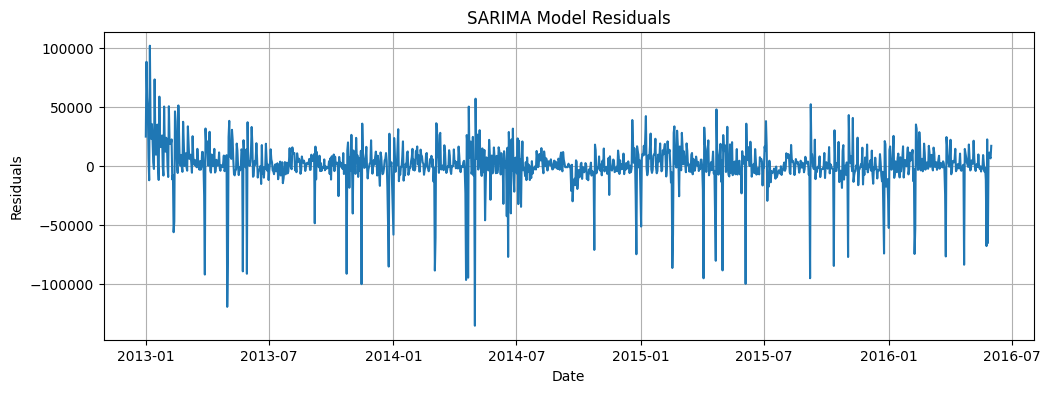

Ljung-Box Test:
      lb_stat  lb_pvalue
7   15.449166   0.030654
14  38.460231   0.000442


In [14]:
from statsmodels.stats.diagnostic import acorr_ljungbox

residuals = sarima_result.resid

plt.figure(figsize=(12, 4))
plt.plot(residuals)
plt.title("SARIMA Model Residuals")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.grid()
plt.show()

print("Ljung-Box Test:")
print(acorr_ljungbox(residuals, lags=[7, 14], return_df=True))

In [15]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_test = acorr_ljungbox(
    sarima_result.resid,
    lags=[7, 14],
    return_df=True
)

print(lb_test)

      lb_stat  lb_pvalue
7   15.449166   0.030654
14  38.460231   0.000442


In [16]:
model2 = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7),
    trend='c',
    enforce_stationarity=False,
    enforce_invertibility=False
)

result2 = model2.fit(disp=False)

print(result2.summary())

                                     SARIMAX Results                                     
Dep. Variable:                   Passenger_Count   No. Observations:                 1247
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood              -14437.860
Date:                           Fri, 20 Nov 2026   AIC                          28887.720
Time:                                   03:27:11   BIC                          28918.448
Sample:                               01-01-2013   HQIC                         28899.277
                                    - 05-31-2016                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   9.556e+04   1.24e+04      7.726      0.000    7.13e+04     1.2e+05
ar.L1         -0.8737      0.094     -9.270

In [17]:
forecast2 = result2.get_forecast(steps=len(test)).predicted_mean
forecast2.index = test.index

mae2 = mean_absolute_error(test, forecast2)
rmse2 = np.sqrt(mean_squared_error(test, forecast2))

print("Second SARIMA Model Evaluation")
print("MAE:", round(mae2, 2))
print("RMSE:", round(rmse2, 2))

Second SARIMA Model Evaluation
MAE: 19275.72
RMSE: 26894.17


In [18]:
comparison = pd.DataFrame({
    'Model': ['SARIMA Model 1', 'SARIMA Model 2'],
    'MAE': [mae, mae2],
    'RMSE': [rmse, rmse2],
    'AIC': [sarima_result.aic, result2.aic]
})

print(comparison.round(2))

comparison.to_csv('SARIMA_Model_Comparison.csv', index=False)

            Model       MAE      RMSE       AIC
0  SARIMA Model 1   8574.28  11262.10  28993.73
1  SARIMA Model 2  19275.72  26894.17  28887.72
